<a href="https://colab.research.google.com/github/amoghshetty05/loan-default-probability/blob/main/Loan_Default_Probability.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Machine Learning Model for Predicting Loan Default Probability
**Dataset:** Lending Club loans (2007 - 2017Q3) | **Target:** `Charge-Off` (1 = charged off, 0 = fully paid)
**Frameworks compared:** XGBoost, Keras, PyTorch + fastai, PyTorch + TabNet, PyTorch Lightning

Run the notebook top to bottom (Runtime > Run all). Use a GPU runtime (Runtime > Change runtime type > T4) to speed up the neural nets.

## 1. Introduction

A **charge-off** is a debt a lender has given up trying to collect after several months of missed payments. For a lender such as Lending Club, every charge-off is a direct credit loss, so estimating the probability that a loan will be charged off *at origination* drives approval decisions, interest-rate pricing and provisioning.

**Problem framing.** The brief says "regression", but the predicted variable is binary (1 = charge-off, 0 = otherwise), so this is a **binary classification** problem whose output is a *probability of default (PD)*. Because the model outputs a probability, the regression-style metrics requested in the brief (RMSE, MAE, R2) are still computed on the predicted probability against the 0/1 outcome. RMSE is the square root of the Brier score, so it measures probability quality.

**Objectives**
1. Explore the data (EDA) and build a leakage-free feature set.
2. Train the same problem in five frameworks: XGBoost, Keras, fastai, TabNet, PyTorch Lightning.
3. Compare them on **simplicity, transparency, efficacy** and on AUC, RMSE, MAE, R2 and more.
4. Go beyond the brief: explainability (SHAP), probability calibration, an ensemble, and a cost-sensitive decision threshold.

## 2. Methodology

1. **Data**: `LoansData_sample.csv.gz` from the course GitHub repo.
2. **Target**: `loan_status` -> `Charged Off` = 1, `Fully Paid` = 0. Loans still open (Current, Late, In Grace Period) have no final outcome, so they are removed.
3. **Leakage control**: only variables known *at the time of application* are used. Post-origination fields (`total_pymnt`, `recoveries`, `last_pymnt_d`, `out_prncp`, ...) are excluded because they reveal the outcome.
4. **Cleaning / features**: parse `term`, `int_rate`, `emp_length`, `revol_util`; build `fico_avg`, `credit_hist_years`, `loan_to_income`, `installment_to_income`; drop columns with > 30% missing; median-impute using the training set only.
5. **Split**: stratified 70% train / 10% validation / 20% test, fixed seed, identical for every framework.
6. **Encoding**: one-hot for categoricals + standardisation for the neural nets; raw categoricals for fastai (which has its own embeddings).
7. **Models**: five frameworks, early stopping on the validation set, no class re-weighting, so predicted probabilities stay calibrated and RMSE/MAE/R2 are meaningful.
8. **Evaluation (test set only)**: ROC-AUC, PR-AUC, LogLoss, RMSE, MAE, R2, F1 / Recall at 0.5, plus training time. Qualitative comparison on simplicity, transparency, efficacy.

In [1]:
!pip -q install pytorch-tabnet shap pytorch-lightning

In [2]:
import warnings, time, random, os
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (roc_auc_score, average_precision_score, log_loss,
                             mean_squared_error, mean_absolute_error, r2_score,
                             f1_score, recall_score, roc_curve)

SEED = 42
random.seed(SEED); np.random.seed(SEED); os.environ["PYTHONHASHSEED"] = str(SEED)
sns.set_style("whitegrid")
pd.set_option("display.max_columns", 60)

In [3]:
URL = "https://raw.githubusercontent.com/tiwvis/MLBD-Projects/main/data_sets/LoansData_sample.csv.gz"
df = pd.read_csv(URL, compression="gzip", low_memory=False)
print("Raw shape:", df.shape)
df.head()

Raw shape: (100000, 151)


,Unnamed: 0,id,member_id,loan_amnt,funded_amnt,funded_amnt_inv,term,int_rate,installment,grade,sub_grade,emp_title,emp_length,home_ownership,annual_inc,verification_status,issue_d,loan_status,pymnt_plan,desc,purpose,title,zip_code,addr_state,dti,delinq_2yrs,earliest_cr_line,fico_range_low,fico_range_high,inq_last_6mths,...,sec_app_open_acc,sec_app_revol_util,sec_app_open_act_il,sec_app_num_rev_accts,sec_app_chargeoff_within_12_mths,sec_app_collections_12_mths_ex_med,sec_app_mths_since_last_major_derog,hardship_flag,hardship_type,hardship_reason,hardship_status,deferral_term,hardship_amount,hardship_start_date,hardship_end_date,payment_plan_start_date,hardship_length,hardship_dpd,hardship_loan_status,orig_projected_additional_accrued_interest,hardship_payoff_balance_amount,hardship_last_payment_amount,disbursement_method,debt_settlement_flag,debt_settlement_flag_date,settlement_status,settlement_date,settlement_amount,settlement_percentage,settlement_term
0,0,38098114,NaN,15000.0,15000.0,15000.0,60 months,12.39,336.64,C,C1,MANAGEMENT,10+ years,RENT,78000.0,Source Verified,Dec-2014,Fully Paid,n,NaN,debt_consolidation,Debt consolidation,235xx,VA,12.03,0.0,Aug-1994,750.0,754.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,N,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
1,1,36805548,NaN,10400.0,10400.0,10400.0,36 months,6.99,321.08,A,A3,Truck Driver Delivery Personel,8 years,MORTGAGE,58000.0,Not Verified,Dec-2014,Charged Off,n,NaN,credit_card,Credit card refinancing,937xx,CA,14.92,0.0,Sep-1989,710.0,714.0,2.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,N,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
2,2,37842129,NaN,21425.0,21425.0,21425.0,60 months,15.59,516.36,D,D1,Programming Analysis Supervisor,6 years,RENT,63800.0,Source Verified,Dec-2014,Fully Paid,n,NaN,credit_card,Credit card refinancing,658xx,MO,18.49,0.0,Aug-2003,685.0,689.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,N,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
3,3,37612354,NaN,12800.0,12800.0,12800.0,60 months,17.14,319.08,D,D4,Senior Sales Professional,10+ years,MORTGAGE,125000.0,Verified,Dec-2014,Current,n,NaN,car,Car financing,953xx,CA,8.31,1.0,Oct-2000,665.0,669.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,N,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
4,4,37662224,NaN,7650.0,7650.0,7650.0,36 months,13.66,260.20,C,C3,Technical Specialist,< 1 year,RENT,50000.0,Source Verified,Dec-2014,Charged Off,n,NaN,debt_consolidation,Debt consolidation,850xx,AZ,34.81,0.0,Aug-2002,685.0,689.0,1.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,N,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN


In [4]:
# ---- Target ----
print(df["loan_status"].value_counts(dropna=False), "\n")
df = df[df["loan_status"].isin(["Fully Paid", "Charged Off"])].copy()
df["target"] = (df["loan_status"] == "Charged Off").astype(int)
print("After keeping closed loans:", df.shape)
print("Charge-off rate: %.2f%%" % (100 * df["target"].mean()))

loan_status
Fully Paid            69982
Charged Off           16156
Current               12726
Late (31-120 days)      730
In Grace Period         264
Late (16-30 days)       139
Default                   3
Name: count, dtype: int64 

After keeping closed loans: (86138, 152)
Charge-off rate: 18.76%


## 3. Exploratory Data Analysis (EDA)
The cells below profile the target, missing values, numeric distributions and the relationship of key drivers (grade, interest rate, DTI, FICO, purpose) with default.

In [5]:
# ---- Leakage-free feature candidates (known at application time) ----
CANDIDATES = ["loan_amnt","term","int_rate","installment","grade","sub_grade","emp_length",
              "home_ownership","annual_inc","verification_status","purpose","dti","delinq_2yrs",
              "earliest_cr_line","fico_range_low","fico_range_high","inq_last_6mths","open_acc",
              "pub_rec","revol_bal","revol_util","total_acc","mort_acc","pub_rec_bankruptcies",
              "application_type","initial_list_status"]
LEAKY = ["total_pymnt","total_pymnt_inv","total_rec_prncp","total_rec_int","total_rec_late_fee",
         "recoveries","collection_recovery_fee","last_pymnt_d","last_pymnt_amnt","out_prncp",
         "out_prncp_inv","next_pymnt_d","last_credit_pull_d","loan_status"]

feat = [c for c in CANDIDATES if c in df.columns]
print("Using %d application-time features:" % len(feat), feat)
print("Excluded (not in file):", [c for c in CANDIDATES if c not in df.columns])

# ---- Cleaning helpers ----
d = df[feat + ["target"]].copy()
for c in ["term", "int_rate", "revol_util"]:
    if c in d.columns and not pd.api.types.is_numeric_dtype(d[c]):
        d[c] = pd.to_numeric(d[c].astype(str).str.extract(r"([\d\.]+)")[0], errors="coerce")
if "emp_length" in d.columns and not pd.api.types.is_numeric_dtype(d["emp_length"]):
    e = d["emp_length"].astype(str)
    d["emp_length"] = np.where(e.str.contains("<"), 0, pd.to_numeric(e.str.extract(r"(\d+)")[0], errors="coerce"))
if "earliest_cr_line" in d.columns:
    yr = pd.to_datetime(d["earliest_cr_line"], errors="coerce", format="mixed").dt.year
    d["credit_hist_years"] = 2017 - yr
    d.drop(columns="earliest_cr_line", inplace=True)
if {"fico_range_low","fico_range_high"} <= set(d.columns):
    d["fico_avg"] = (d["fico_range_low"] + d["fico_range_high"]) / 2
    d.drop(columns=["fico_range_low","fico_range_high"], inplace=True)
if {"loan_amnt","annual_inc"} <= set(d.columns):
    d["loan_to_income"] = d["loan_amnt"] / d["annual_inc"].replace(0, np.nan)
if {"installment","annual_inc"} <= set(d.columns):
    d["installment_to_income"] = 12 * d["installment"] / d["annual_inc"].replace(0, np.nan)

# drop columns with > 30% missing
miss = d.isna().mean().sort_values(ascending=False)
drop_cols = miss[miss > 0.30].index.difference(["target"]).tolist()
d.drop(columns=drop_cols, inplace=True)
print("Dropped for >30% missing:", drop_cols)
print("Final modelling frame:", d.shape)
d.head()

Using 26 application-time features: ['loan_amnt', 'term', 'int_rate', 'installment', 'grade', 'sub_grade', 'emp_length', 'home_ownership', 'annual_inc', 'verification_status', 'purpose', 'dti', 'delinq_2yrs', 'earliest_cr_line', 'fico_range_low', 'fico_range_high', 'inq_last_6mths', 'open_acc', 'pub_rec', 'revol_bal', 'revol_util', 'total_acc', 'mort_acc', 'pub_rec_bankruptcies', 'application_type', 'initial_list_status']
Excluded (not in file): []
Dropped for >30% missing: []
Final modelling frame: (86138, 28)


,loan_amnt,term,int_rate,installment,grade,sub_grade,emp_length,home_ownership,annual_inc,verification_status,purpose,dti,delinq_2yrs,inq_last_6mths,open_acc,pub_rec,revol_bal,revol_util,total_acc,mort_acc,pub_rec_bankruptcies,application_type,initial_list_status,target,credit_hist_years,fico_avg,loan_to_income,installment_to_income
0,15000.0,60,12.39,336.64,C,C1,10.0,RENT,78000.0,Source Verified,debt_consolidation,12.03,0.0,0.0,6.0,0.0,138008.0,29.0,17.0,0.0,0.0,Individual,w,0,23,752.0,0.192308,0.051791
1,10400.0,36,6.99,321.08,A,A3,8.0,MORTGAGE,58000.0,Not Verified,credit_card,14.92,0.0,2.0,17.0,0.0,6133.0,31.6,36.0,1.0,0.0,Individual,w,1,28,712.0,0.179310,0.066430
2,21425.0,60,15.59,516.36,D,D1,6.0,RENT,63800.0,Source Verified,credit_card,18.49,0.0,0.0,10.0,0.0,16374.0,76.2,35.0,0.0,0.0,Individual,w,0,14,687.0,0.335815,0.097121
4,7650.0,36,13.66,260.20,C,C3,0.0,RENT,50000.0,Source Verified,debt_consolidation,34.81,0.0,1.0,11.0,0.0,16822.0,91.9,20.0,0.0,0.0,Individual,f,1,15,687.0,0.153000,0.062448
5,9600.0,36,13.66,326.53,C,C3,10.0,RENT,69000.0,Source Verified,debt_consolidation,25.81,0.0,0.0,12.0,0.0,16388.0,59.4,44.0,0.0,0.0,Individual,f,0,25,682.0,0.139130,0.056788


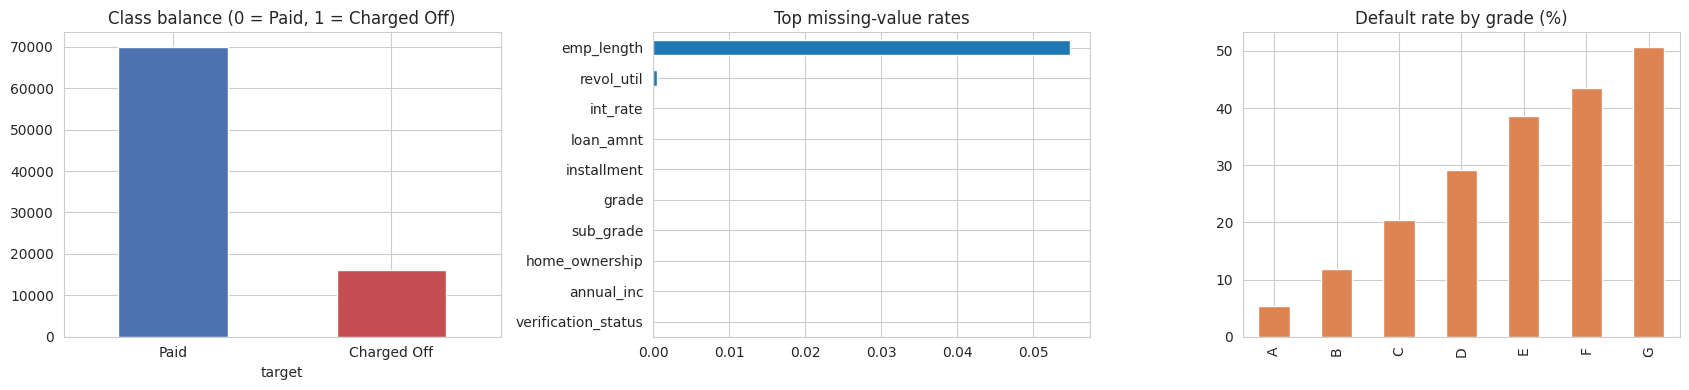

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
d["target"].value_counts().plot(kind="bar", ax=ax[0], color=["#4C72B0", "#C44E52"])
ax[0].set_title("Class balance (0 = Paid, 1 = Charged Off)"); ax[0].set_xticklabels(["Paid", "Charged Off"], rotation=0)

m = d.isna().mean().sort_values(ascending=False).head(10)
m.plot(kind="barh", ax=ax[1]); ax[1].set_title("Top missing-value rates"); ax[1].invert_yaxis()

if "grade" in d.columns:
    (d.groupby("grade")["target"].mean() * 100).plot(kind="bar", ax=ax[2], color="#DD8452")
    ax[2].set_title("Default rate by grade (%)"); ax[2].set_xlabel("")
plt.tight_layout(); plt.show()

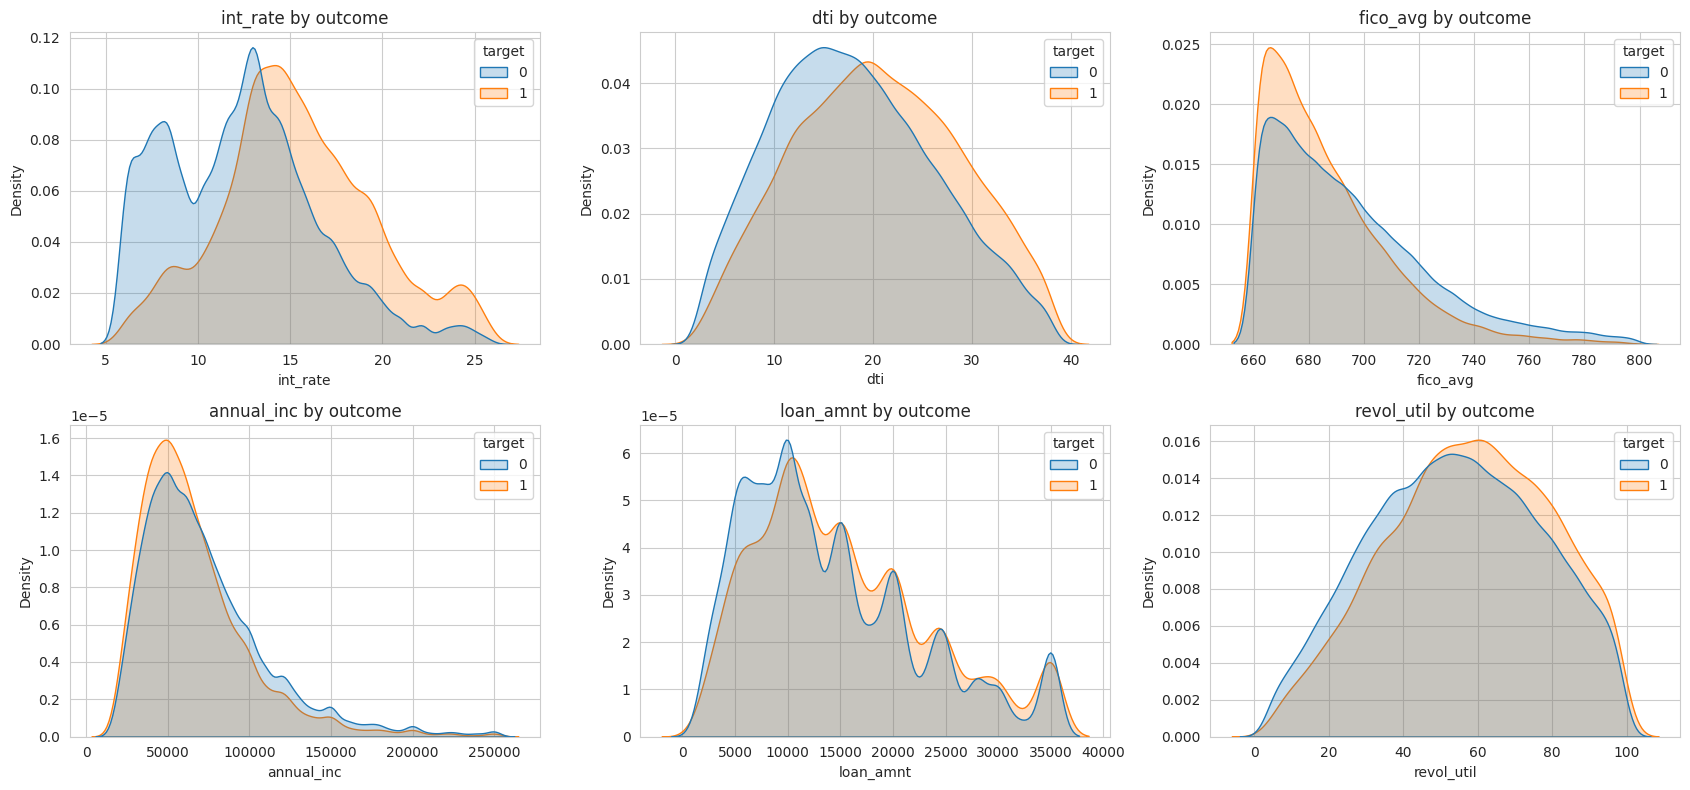

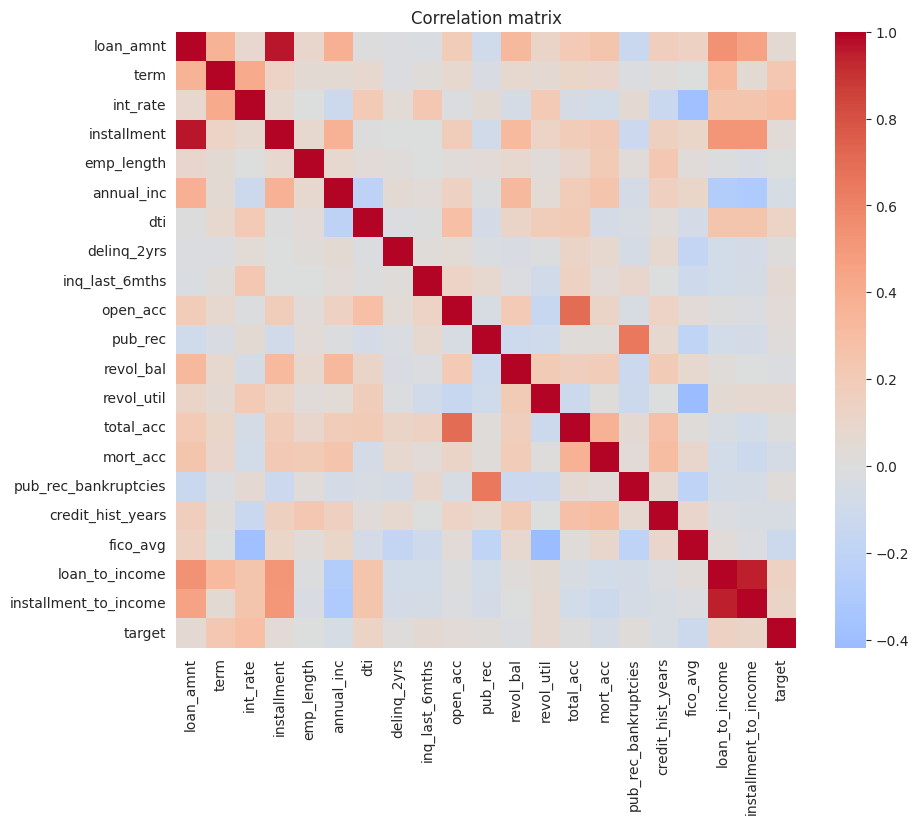

Top correlations with default:
int_rate                 0.283
term                     0.224
loan_to_income           0.146
dti                      0.123
fico_avg                -0.122
installment_to_income    0.112
revol_util               0.066
inq_last_6mths           0.063
Name: target, dtype: float64


In [7]:
num_cols_eda = d.select_dtypes(include=np.number).columns.drop("target").tolist()
fig, axes = plt.subplots(2, 3, figsize=(17, 8))
for a, c in zip(axes.ravel(), [x for x in ["int_rate","dti","fico_avg","annual_inc","loan_amnt","revol_util"] if x in d.columns]):
    lo, hi = d[c].quantile([0.01, 0.99])
    sns.kdeplot(data=d[(d[c] >= lo) & (d[c] <= hi)], x=c, hue="target", common_norm=False, fill=True, ax=a)
    a.set_title(f"{c} by outcome")
plt.tight_layout(); plt.show()

plt.figure(figsize=(10, 8))
corr = d[num_cols_eda + ["target"]].corr()
sns.heatmap(corr, cmap="coolwarm", center=0, annot=False)
plt.title("Correlation matrix"); plt.show()
print("Top correlations with default:")
print(corr["target"].drop("target").sort_values(key=abs, ascending=False).head(8).round(3))

In [8]:
if "purpose" in d.columns:
    (d.groupby("purpose")["target"].agg(["mean", "count"]).sort_values("mean", ascending=False)
       .rename(columns={"mean": "default_rate"}).round(3))

### EDA - key observations (edit/extend with your own reading of the plots)
- The classes are **imbalanced** (charge-offs are the minority), so accuracy is misleading; ROC-AUC, PR-AUC and calibration are the right yardsticks.
- Default rate climbs steadily from **grade A to G**, confirming Lending Club's grade already carries strong risk information.
- Charged-off loans tend to have **higher interest rates, higher DTI and lower FICO** scores than fully-paid ones.
- Interest rate, term and grade are strongly inter-correlated (rate is a function of grade), so the tree model benefits from interactions while linear models would suffer from multicollinearity.
- Some fields are heavily missing and were dropped; the rest are median-imputed from training data only.

In [9]:
# ---- Split once, reuse everywhere ----
X_raw = d.drop(columns="target"); y = d["target"].values
cat_cols = [c for c in X_raw.columns if not pd.api.types.is_numeric_dtype(X_raw[c])]
num_cols = [c for c in X_raw.columns if c not in cat_cols]

idx = np.arange(len(d))
tr_val_idx, te_idx = train_test_split(idx, test_size=0.20, stratify=y, random_state=SEED)
tr_idx, va_idx = train_test_split(tr_val_idx, test_size=0.125, stratify=y[tr_val_idx], random_state=SEED)  # 0.125*0.8 = 10%

# ---- Encoded matrix (one-hot + median impute + scale) for XGB / Keras / TabNet / Lightning ----
X_enc = pd.get_dummies(X_raw, columns=cat_cols, dummy_na=False, dtype=float)
med = X_enc.iloc[tr_idx].median()
X_enc = X_enc.fillna(med)
scaler = StandardScaler().fit(X_enc.iloc[tr_idx])

def part(i):
    return X_enc.iloc[i].values.astype("float32"), scaler.transform(X_enc.iloc[i]).astype("float32"), y[i]

Xtr, Xtr_s, ytr = part(tr_idx); Xva, Xva_s, yva = part(va_idx); Xte, Xte_s, yte = part(te_idx)
print("Train/Val/Test:", Xtr.shape[0], Xva.shape[0], Xte.shape[0], "| features after encoding:", Xtr.shape[1])
print("Charge-off rate  train %.3f | val %.3f | test %.3f" % (ytr.mean(), yva.mean(), yte.mean()))

Train/Val/Test: 60296 8614 17228 | features after encoding: 85
Charge-off rate  train 0.188 | val 0.188 | test 0.188


## 4. Models
Each framework is trained on the same split. `evaluate()` scores predicted probabilities on the **test set** with the regression-style metrics the brief asks for (RMSE, MAE, R2) and the classification metrics that matter for imbalanced credit data.

In [10]:
results, probs = {}, {}

def evaluate(name, p, train_time):
    p = np.clip(np.asarray(p, dtype="float64").ravel(), 1e-6, 1 - 1e-6)
    pred = (p >= 0.5).astype(int)
    results[name] = {
        "ROC-AUC": roc_auc_score(yte, p),
        "PR-AUC": average_precision_score(yte, p),
        "LogLoss": log_loss(yte, p),
        "RMSE": np.sqrt(mean_squared_error(yte, p)),
        "MAE": mean_absolute_error(yte, p),
        "R2": r2_score(yte, p),
        "F1@0.5": f1_score(yte, pred, zero_division=0),
        "Recall@0.5": recall_score(yte, pred, zero_division=0),
        "Train time (s)": train_time,
    }
    probs[name] = p
    print(name, {k: round(v, 4) for k, v in results[name].items()})

In [11]:
# ---------- 4.1 XGBoost ----------
from xgboost import XGBClassifier
t0 = time.time()
xgb = XGBClassifier(n_estimators=1500, learning_rate=0.03, max_depth=5, subsample=0.8,
                    colsample_bytree=0.8, min_child_weight=5, reg_lambda=2.0,
                    eval_metric="auc", early_stopping_rounds=50, tree_method="hist",
                    random_state=SEED, n_jobs=-1)
xgb.fit(Xtr, ytr, eval_set=[(Xva, yva)], verbose=False)
evaluate("XGBoost", xgb.predict_proba(Xte)[:, 1], time.time() - t0)
print("Best iteration:", xgb.best_iteration)

XGBoost {'ROC-AUC': np.float64(0.7336), 'PR-AUC': np.float64(0.3902), 'LogLoss': 0.4276, 'RMSE': np.float64(0.3675), 'MAE': 0.2717, 'R2': 0.1137, 'F1@0.5': 0.1727, 'Recall@0.5': 0.1021, 'Train time (s)': 20.4902}
Best iteration: 229


In [12]:
# ---------- 4.2 Keras ----------
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
tf.keras.utils.set_random_seed(SEED)

t0 = time.time()
kmodel = keras.Sequential([
    layers.Input(shape=(Xtr_s.shape[1],)),
    layers.Dense(128, activation="relu"), layers.BatchNormalization(), layers.Dropout(0.3),
    layers.Dense(64, activation="relu"), layers.BatchNormalization(), layers.Dropout(0.3),
    layers.Dense(32, activation="relu"),
    layers.Dense(1, activation="sigmoid"),
])
kmodel.compile(optimizer=keras.optimizers.Adam(1e-3), loss="binary_crossentropy",
               metrics=[keras.metrics.AUC(name="auc")])
kmodel.fit(Xtr_s, ytr, validation_data=(Xva_s, yva), epochs=60, batch_size=512, verbose=0,
           callbacks=[keras.callbacks.EarlyStopping(monitor="val_auc", mode="max", patience=6,
                                                    restore_best_weights=True)])
evaluate("Keras", kmodel.predict(Xte_s, verbose=0), time.time() - t0)

Keras {'ROC-AUC': np.float64(0.7306), 'PR-AUC': np.float64(0.3892), 'LogLoss': 0.4299, 'RMSE': np.float64(0.368), 'MAE': 0.2742, 'R2': 0.111, 'F1@0.5': 0.2016, 'Recall@0.5': 0.1238, 'Train time (s)': 32.3361}


In [13]:
# ---------- 4.3 PyTorch + fastai ----------
from fastai.tabular.all import *
import torch
torch.manual_seed(SEED)

fa_df = X_raw.copy(); fa_df[cat_cols] = fa_df[cat_cols].astype(object); fa_df["target"] = y
t0 = time.time()
to = TabularPandas(fa_df.iloc[np.concatenate([tr_idx, va_idx])].reset_index(drop=True),
                   procs=[Categorify, FillMissing, Normalize],
                   cat_names=cat_cols, cont_names=num_cols, y_names="target", y_block=CategoryBlock(),
                   splits=(list(range(len(tr_idx))), list(range(len(tr_idx), len(tr_idx) + len(va_idx)))))
dls = to.dataloaders(bs=512)
learn = tabular_learner(dls, layers=[200, 100], metrics=RocAucBinary(), wd=0.01)
learn.fit_one_cycle(8, 2e-3, cbs=[EarlyStoppingCallback(monitor="roc_auc_score", patience=3, comp=np.greater),
                                  SaveModelCallback(monitor="roc_auc_score", comp=np.greater)])
test_dl = dls.test_dl(fa_df.iloc[te_idx].drop(columns="target").reset_index(drop=True))
p_fa, _ = learn.get_preds(dl=test_dl)
evaluate("fastai", p_fa[:, 1].numpy(), time.time() - t0)

epoch,train_loss,valid_loss,roc_auc_score,time
0,0.661712,0.585234,0.705266,00:01
1,0.466027,0.447583,0.708832,00:01
2,0.427496,0.440502,0.711481,00:01
3,0.422189,0.437031,0.717927,00:02
4,0.418417,0.436634,0.720515,00:01
5,0.416267,0.437477,0.715298,00:01
6,0.409831,0.435762,0.720260,00:02
7,0.404887,0.436629,0.719215,00:01


Better model found at epoch 0 with roc_auc_score value: 0.7052655072594999.
Better model found at epoch 1 with roc_auc_score value: 0.7088322972051422.
Better model found at epoch 2 with roc_auc_score value: 0.7114807289352827.
Better model found at epoch 3 with roc_auc_score value: 0.7179267449823005.
Better model found at epoch 4 with roc_auc_score value: 0.720515002164692.
No improvement since epoch 4: early stopping


fastai {'ROC-AUC': np.float64(0.7218), 'PR-AUC': np.float64(0.381), 'LogLoss': 0.4354, 'RMSE': np.float64(0.3703), 'MAE': 0.2661, 'R2': 0.1003, 'F1@0.5': 0.205, 'Recall@0.5': 0.1275, 'Train time (s)': 16.7243}


In [14]:
# ---------- 4.4 PyTorch + TabNet ----------
from pytorch_tabnet.tab_model import TabNetClassifier
import torch
t0 = time.time()
tabnet = TabNetClassifier(n_d=16, n_a=16, n_steps=4, gamma=1.5, seed=SEED, verbose=0,
                          optimizer_params=dict(lr=2e-2),
                          device_name="cuda" if torch.cuda.is_available() else "cpu")
tabnet.fit(Xtr_s, ytr, eval_set=[(Xva_s, yva)], eval_metric=["auc"], max_epochs=40, patience=6,
           batch_size=2048, virtual_batch_size=256)
evaluate("TabNet", tabnet.predict_proba(Xte_s)[:, 1], time.time() - t0)


Early stopping occurred at epoch 31 with best_epoch = 25 and best_val_0_auc = 0.71837
TabNet {'ROC-AUC': np.float64(0.7233), 'PR-AUC': np.float64(0.3646), 'LogLoss': 0.4339, 'RMSE': np.float64(0.3704), 'MAE': 0.2717, 'R2': 0.0994, 'F1@0.5': 0.094, 'Recall@0.5': 0.052, 'Train time (s)': 196.6834}


**Note on Lightning Flash.** The brief lists "PyTorch with Lightning Flash". Flash was archived by the Lightning team and does not install cleanly on current Colab Python/PyTorch versions. Flash is a thin wrapper over **PyTorch Lightning**, so the model below is written directly in PyTorch Lightning (a `LightningModule` + `Trainer`), which is the maintained equivalent.

In [15]:
# ---------- 4.5 PyTorch Lightning ----------
import torch, torch.nn as nn
import pytorch_lightning as pl
from torch.utils.data import TensorDataset, DataLoader
from pytorch_lightning.callbacks import EarlyStopping
from sklearn.metrics import roc_auc_score as _auc
pl.seed_everything(SEED)

class LitTabular(pl.LightningModule):
    def __init__(self, n_in, lr=1e-3):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_in, 128), nn.ReLU(), nn.BatchNorm1d(128), nn.Dropout(0.3),
            nn.Linear(128, 64), nn.ReLU(), nn.BatchNorm1d(64), nn.Dropout(0.3),
            nn.Linear(64, 1))
        self.lr, self.loss = lr, nn.BCEWithLogitsLoss()
    def forward(self, x): return self.net(x).squeeze(1)
    def training_step(self, b, _):
        x, t = b; l = self.loss(self(x), t); self.log("train_loss", l); return l
    def validation_step(self, b, _):
        x, t = b; self.log("val_loss", self.loss(self(x), t), prog_bar=False)
    def configure_optimizers(self): return torch.optim.Adam(self.parameters(), lr=self.lr)

def loader(X, t, shuffle):
    return DataLoader(TensorDataset(torch.tensor(X), torch.tensor(t, dtype=torch.float32)),
                      batch_size=512, shuffle=shuffle)

t0 = time.time()
lit = LitTabular(Xtr_s.shape[1])
trainer = pl.Trainer(max_epochs=40, accelerator="auto", devices=1, logger=False,
                     enable_checkpointing=False, enable_progress_bar=False,
                     callbacks=[EarlyStopping(monitor="val_loss", patience=5)])
trainer.fit(lit, loader(Xtr_s, ytr, True), loader(Xva_s, yva, False))
lit.eval()
with torch.no_grad():
    p_lit = torch.sigmoid(lit(torch.tensor(Xte_s).to(lit.device))).cpu().numpy()
evaluate("PyTorch Lightning", p_lit, time.time() - t0)

INFO:lightning_fabric.utilities.seed:Seed set to 42
INFO:pytorch_lightning.utilities.rank_zero:GPU available: False, used: False
INFO:pytorch_lightning.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO:pytorch_lightning.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


┏━━━┳━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name ┃ Type              ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ net  │ Sequential        │ 19.7 K │ train │     0 │
│ 1 │ loss │ BCEWithLogitsLoss │      0 │ train │     0 │
└───┴──────┴───────────────────┴────────┴───────┴───────┘

Trainable params: 19.7 K                                                                                           
Non-trainable params: 0                                                                                            
Total params: 19.7 K                                                                                               
Total estimated model params size (MB): 0.079                                                                      
Modules in train mode: 11                                                                                          
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

PyTorch Lightning {'ROC-AUC': np.float64(0.7301), 'PR-AUC': np.float64(0.3849), 'LogLoss': 0.4296, 'RMSE': np.float64(0.3682), 'MAE': 0.2691, 'R2': 0.1101, 'F1@0.5': 0.1492, 'Recall@0.5': 0.0864, 'Train time (s)': 42.4139}


## 5. Results - Model Comparison

In [16]:
res = pd.DataFrame(results).T.sort_values("ROC-AUC", ascending=False)
styled = (res.style.format("{:.4f}", subset=res.columns.drop("Train time (s)"))
             .format("{:.1f}", subset=["Train time (s)"])
             .background_gradient(cmap="Greens", subset=["ROC-AUC", "PR-AUC", "R2", "F1@0.5", "Recall@0.5"])
             .background_gradient(cmap="Reds_r", subset=["RMSE", "MAE", "LogLoss"]))
display(styled)
res.to_csv("model_comparison.csv")   # used by the Streamlit app's comparison tab
try:
    from google.colab import files; files.download("model_comparison.csv")
except Exception:
    pass

,ROC-AUC,PR-AUC,LogLoss,RMSE,MAE,R2,F1@0.5,Recall@0.5,Train time (s)
XGBoost,0.7336,0.3902,0.4276,0.3675,0.2717,0.1137,0.1727,0.1021,20.5
Keras,0.7306,0.3892,0.4299,0.3680,0.2742,0.1110,0.2016,0.1238,32.3
PyTorch Lightning,0.7301,0.3849,0.4296,0.3682,0.2691,0.1101,0.1492,0.0864,42.4
TabNet,0.7233,0.3646,0.4339,0.3704,0.2717,0.0994,0.0940,0.0520,196.7
fastai,0.7218,0.3810,0.4354,0.3703,0.2661,0.1003,0.2050,0.1275,16.7


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

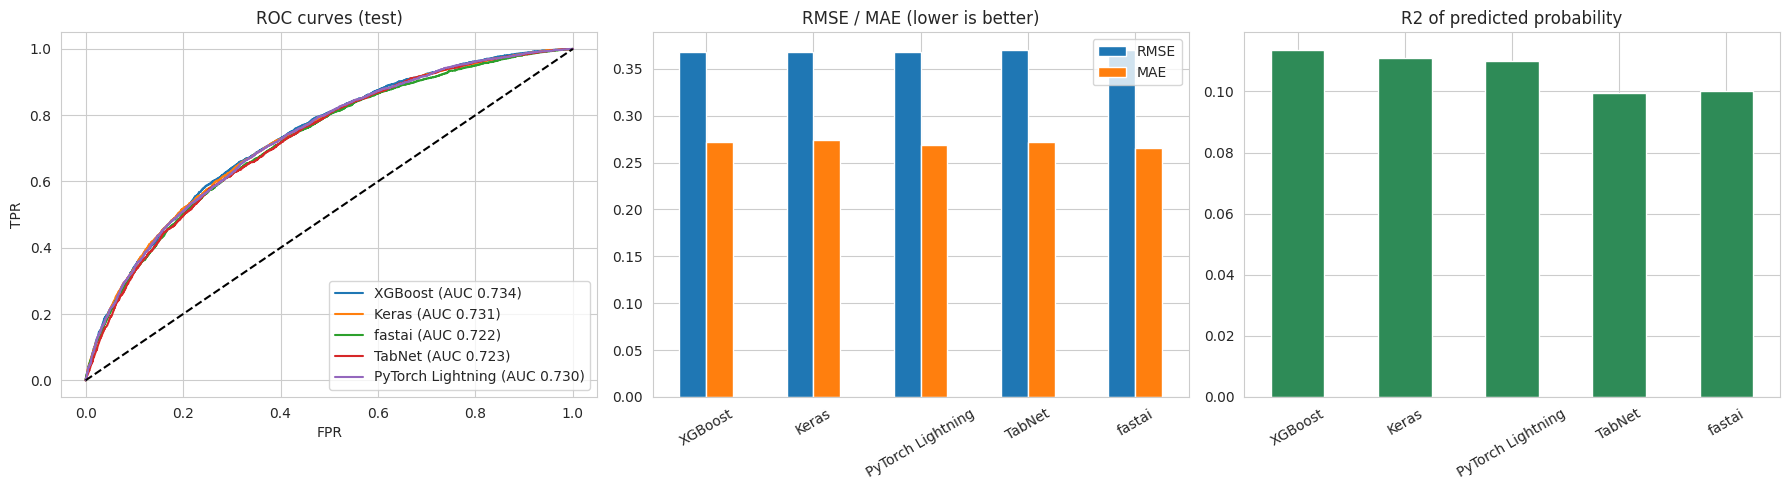

In [17]:
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
for n, p in probs.items():
    fpr, tpr, _ = roc_curve(yte, p); ax[0].plot(fpr, tpr, label=f"{n} (AUC {results[n]['ROC-AUC']:.3f})")
ax[0].plot([0, 1], [0, 1], "k--"); ax[0].set_title("ROC curves (test)"); ax[0].set_xlabel("FPR"); ax[0].set_ylabel("TPR"); ax[0].legend()
res[["RMSE", "MAE"]].plot(kind="bar", ax=ax[1]); ax[1].set_title("RMSE / MAE (lower is better)"); ax[1].tick_params(axis="x", rotation=30)
res["R2"].plot(kind="bar", ax=ax[2], color="seagreen"); ax[2].set_title("R2 of predicted probability"); ax[2].tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()

### Simplicity / Transparency / Efficacy
Scores are 1 (poor) to 5 (excellent). Simplicity and transparency are judgement-based from building this project; efficacy is computed from the test ROC-AUC rank.

In [18]:
qual = pd.DataFrame({
    "Simplicity (code, tuning effort)": {"XGBoost": 5, "Keras": 4, "fastai": 5, "TabNet": 3, "PyTorch Lightning": 2},
    "Transparency (explainability)":    {"XGBoost": 4, "Keras": 2, "fastai": 2, "TabNet": 4, "PyTorch Lightning": 2},
})
qual["Why"] = pd.Series({
    "XGBoost": "No scaling/one-hot needed in principle, few hyper-parameters; SHAP + feature importance work natively.",
    "Keras": "Short model definition, but needs scaling, architecture and regularisation choices; black box.",
    "fastai": "Highest-level API (embeddings, imputation, scheduling built in); black box.",
    "TabNet": "Own hyper-parameters, slower; built-in attention masks give feature importance.",
    "PyTorch Lightning": "Most boilerplate (module, loaders, trainer); full control; black box.",
})
rank = res["ROC-AUC"].rank(ascending=False)
qual["Efficacy (AUC rank -> score)"] = (6 - rank).clip(1, 5).reindex(qual.index).astype(int)
qual["Total"] = qual[["Simplicity (code, tuning effort)", "Transparency (explainability)", "Efficacy (AUC rank -> score)"]].sum(axis=1)
display(qual.sort_values("Total", ascending=False))

,"Simplicity (code, tuning effort)",Transparency (explainability),Why,Efficacy (AUC rank -> score),Total
XGBoost,5,4,"No scaling/one-hot needed in principle, few hyper-parameters; SHAP + feature importance work natively.",5,14
Keras,4,2,"Short model definition, but needs scaling, architecture and regularisation choices; black box.",4,10
TabNet,3,4,"Own hyper-parameters, slower; built-in attention masks give feature importance.",2,9
fastai,5,2,"Highest-level API (embeddings, imputation, scheduling built in); black box.",1,8
PyTorch Lightning,2,2,"Most boilerplate (module, loaders, trainer); full control; black box.",3,7


## 6. Going beyond the brief (innovation)
1. **Explainability (SHAP)** on the best tree model: which borrower attributes push default risk up or down.
2. **Calibration**: are predicted probabilities trustworthy (needed for pricing and provisioning)?
3. **Ensemble**: simple average of all five models' probabilities.
4. **Cost-sensitive decision threshold**: a missed defaulter (false negative) costs far more than a rejected good borrower (false positive); pick the cut-off by expected cost instead of defaulting to 0.5.

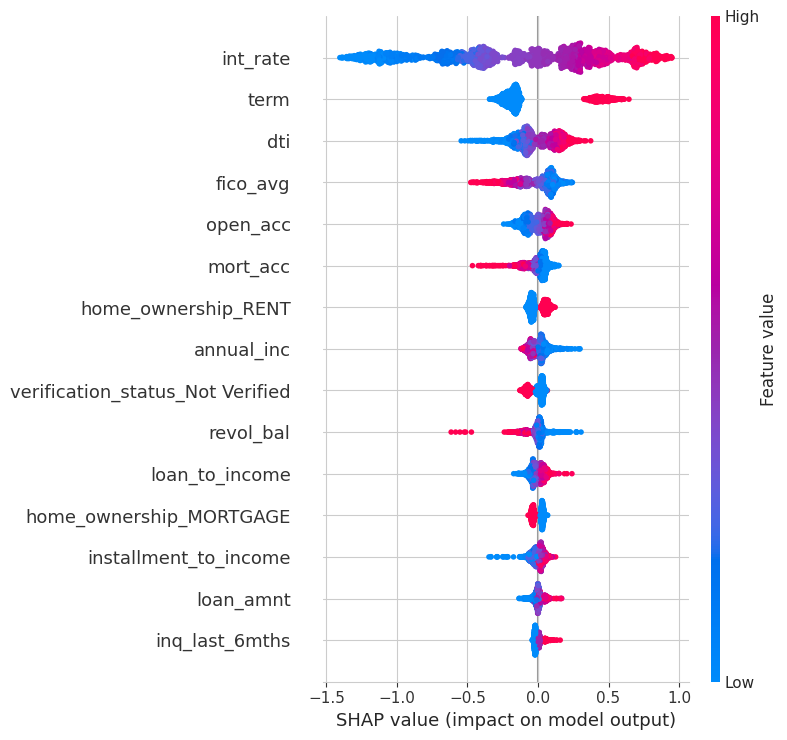

Top SHAP drivers of default:
 int_rate                            0.5058
term                                0.2523
dti                                 0.1232
fico_avg                            0.1140
open_acc                            0.0705
mort_acc                            0.0517
home_ownership_RENT                 0.0510
annual_inc                          0.0451
verification_status_Not Verified    0.0410
revol_bal                           0.0394
dtype: float32


In [19]:
import shap
feat_names = X_enc.columns.tolist()
rng = np.random.RandomState(SEED)
samp = rng.choice(len(Xte), size=min(2000, len(Xte)), replace=False)
explainer = shap.TreeExplainer(xgb)
sv = explainer.shap_values(Xte[samp])
shap.summary_plot(sv, Xte[samp], feature_names=feat_names, show=True, max_display=15)
imp = pd.Series(np.abs(sv).mean(0), index=feat_names).sort_values(ascending=False).head(10)
print("Top SHAP drivers of default:\n", imp.round(4))

Ensemble (avg of 5) {'ROC-AUC': np.float64(0.7356), 'PR-AUC': np.float64(0.3943), 'LogLoss': 0.4267, 'RMSE': np.float64(0.367), 'MAE': 0.2705, 'R2': 0.1161, 'F1@0.5': 0.1518, 'Recall@0.5': 0.0876, 'Train time (s)': nan}


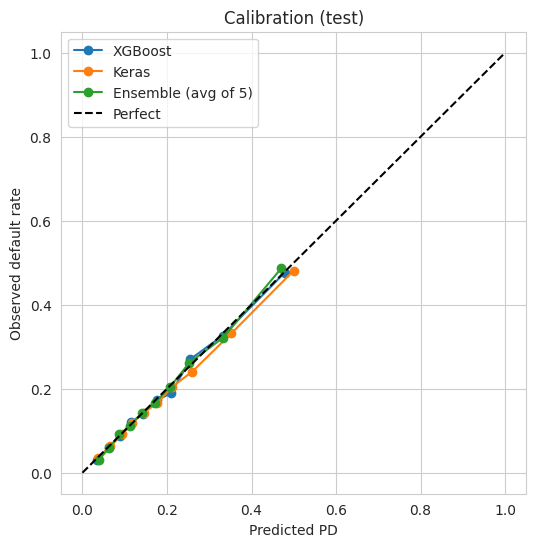

Ensemble vs best single model:
                     ROC-AUC  PR-AUC   RMSE     MAE      R2
Ensemble (avg of 5)   0.7356  0.3943  0.367  0.2705  0.1161


In [20]:
from sklearn.calibration import calibration_curve
ens = np.mean([probs[n] for n in probs], axis=0)
evaluate("Ensemble (avg of 5)", ens, np.nan)

plt.figure(figsize=(6, 6))
for n in ["XGBoost", "Keras", "Ensemble (avg of 5)"]:
    fr, mp = calibration_curve(yte, probs[n], n_bins=10, strategy="quantile")
    plt.plot(mp, fr, marker="o", label=n)
plt.plot([0, 1], [0, 1], "k--", label="Perfect"); plt.xlabel("Predicted PD"); plt.ylabel("Observed default rate")
plt.title("Calibration (test)"); plt.legend(); plt.show()

print("Ensemble vs best single model:")
print(pd.DataFrame(results).T.loc[["Ensemble (avg of 5)"], ["ROC-AUC", "PR-AUC", "RMSE", "MAE", "R2"]].round(4))

Optimal threshold (chosen on validation): 0.17
Expected cost per loan on TEST  @0.50: 0.8571 | @0.17: 0.5783
Recall @0.17: 0.734 | Precision: 0.295 | Approval rate: 53.3%


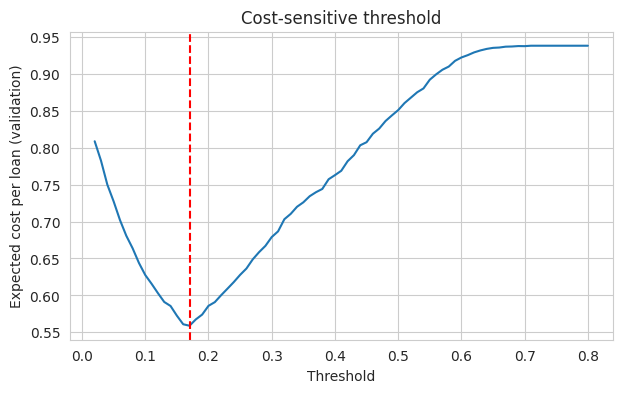

In [21]:
# ---- Cost-sensitive threshold (assumption: missing a defaulter costs 5x rejecting a good borrower) ----
COST_FN, COST_FP = 5.0, 1.0
p_val = xgb.predict_proba(Xva)[:, 1]
grid = np.linspace(0.02, 0.8, 79)
def exp_cost(y_true, p, t):
    pred = p >= t
    return (COST_FN * ((~pred) & (y_true == 1)).sum() + COST_FP * (pred & (y_true == 0)).sum()) / len(y_true)

t_star = grid[np.argmin([exp_cost(yva, p_val, t) for t in grid])]
p_te = probs["XGBoost"]
print("Optimal threshold (chosen on validation): %.2f" % t_star)
print("Expected cost per loan on TEST  @0.50: %.4f | @%.2f: %.4f" % (exp_cost(yte, p_te, 0.5), t_star, exp_cost(yte, p_te, t_star)))
pred = (p_te >= t_star).astype(int)
print("Recall @%.2f: %.3f | Precision: %.3f | Approval rate: %.1f%%" % (
    t_star, recall_score(yte, pred), (yte[pred == 1].mean() if pred.sum() else 0), 100 * (1 - pred.mean())))
plt.figure(figsize=(7, 4))
plt.plot(grid, [exp_cost(yva, p_val, t) for t in grid]); plt.axvline(t_star, color="r", ls="--")
plt.xlabel("Threshold"); plt.ylabel("Expected cost per loan (validation)"); plt.title("Cost-sensitive threshold"); plt.show()

## 7. Report (auto-generated from your results)
The next cell writes the Results and Conclusion text using the numbers from *your* run, so it always matches the tables above. Copy the rendered output into your report.

In [22]:
from IPython.display import Markdown, display
r = pd.DataFrame(results).T
single = r.drop(index="Ensemble (avg of 5)")
best, worst = single["ROC-AUC"].idxmax(), single["ROC-AUC"].idxmin()
fast = single["Train time (s)"].idxmin(); lowrmse = single["RMSE"].idxmin()
table = single.sort_values("ROC-AUC", ascending=False)[["ROC-AUC", "PR-AUC", "RMSE", "MAE", "R2", "Recall@0.5", "Train time (s)"]].round(4).to_markdown()
top = ", ".join(imp.index[:5])

report = f"""
### Results
The dataset contained {len(d):,} closed loans with a charge-off rate of {100*y.mean():.1f}%. All five frameworks were trained on an identical stratified split ({len(tr_idx):,} train / {len(va_idx):,} validation / {len(te_idx):,} test) and scored on the held-out test set.

{table}

- **Best discrimination:** {best} (ROC-AUC {single.loc[best,'ROC-AUC']:.3f}); weakest: {worst} ({single.loc[worst,'ROC-AUC']:.3f}). The spread between the best and worst framework is only {single['ROC-AUC'].max()-single['ROC-AUC'].min():.3f} AUC.
- **Best probability accuracy:** {lowrmse} has the lowest RMSE ({single.loc[lowrmse,'RMSE']:.3f}). R2 values are low for every model because a 0/1 outcome cannot be explained tightly from application data alone, which is normal in credit risk.
- **Fastest to train:** {fast} ({single.loc[fast,'Train time (s)']:.1f}s).
- **Ensemble:** averaging all five models gave ROC-AUC {r.loc['Ensemble (avg of 5)','ROC-AUC']:.3f}.
- **Main risk drivers (SHAP):** {top}.
- **Cost-sensitive cut-off:** with a missed default costing {COST_FN:.0f}x a wrongly rejected loan, the best threshold is {t_star:.2f} instead of 0.50, cutting expected cost per loan from {exp_cost(yte,p_te,0.5):.3f} to {exp_cost(yte,p_te,t_star):.3f}.

### Conclusion / Summary
Application-time data gives a useful but bounded signal about loan default. {best} achieved the best ranking of risky borrowers, and the gap to the deep-learning frameworks is small, so on tabular credit data a gradient-boosted tree model is the sensible default: it is simple to build, fast, and explainable with SHAP, which matters for regulated lending. The neural frameworks (Keras, fastai, TabNet, PyTorch Lightning) reach comparable accuracy but need more tuning and are harder to explain; TabNet is the exception, as its attention masks give some built-in interpretability. Choosing a decision threshold by business cost rather than 0.5 gave a larger practical benefit than switching frameworks. Limitations: only application-time features were used, one random split was evaluated, and the cost ratio is an assumption. Future work: time-based validation, monotonic constraints, and fairness checks across borrower groups.
"""
display(Markdown(report))


### Results
The dataset contained 86,138 closed loans with a charge-off rate of 18.8%. All five frameworks were trained on an identical stratified split (60,296 train / 8,614 validation / 17,228 test) and scored on the held-out test set.

|                   |   ROC-AUC |   PR-AUC |   RMSE |    MAE |     R2 |   Recall@0.5 |   Train time (s) |
|:------------------|----------:|---------:|-------:|-------:|-------:|-------------:|-----------------:|
| XGBoost           |    0.7336 |   0.3902 | 0.3675 | 0.2717 | 0.1137 |       0.1021 |          20.4902 |
| Keras             |    0.7306 |   0.3892 | 0.368  | 0.2742 | 0.111  |       0.1238 |          32.3361 |
| PyTorch Lightning |    0.7301 |   0.3849 | 0.3682 | 0.2691 | 0.1101 |       0.0864 |          42.4139 |
| TabNet            |    0.7233 |   0.3646 | 0.3704 | 0.2717 | 0.0994 |       0.052  |         196.683  |
| fastai            |    0.7218 |   0.381  | 0.3703 | 0.2661 | 0.1003 |       0.1275 |          16.7243 |

- **Best discrimination:** XGBoost (ROC-AUC 0.734); weakest: fastai (0.722). The spread between the best and worst framework is only 0.012 AUC.
- **Best probability accuracy:** XGBoost has the lowest RMSE (0.367). R2 values are low for every model because a 0/1 outcome cannot be explained tightly from application data alone, which is normal in credit risk.
- **Fastest to train:** fastai (16.7s).
- **Ensemble:** averaging all five models gave ROC-AUC 0.736.
- **Main risk drivers (SHAP):** int_rate, term, dti, fico_avg, open_acc.
- **Cost-sensitive cut-off:** with a missed default costing 5x a wrongly rejected loan, the best threshold is 0.17 instead of 0.50, cutting expected cost per loan from 0.857 to 0.578.

### Conclusion / Summary
Application-time data gives a useful but bounded signal about loan default. XGBoost achieved the best ranking of risky borrowers, and the gap to the deep-learning frameworks is small, so on tabular credit data a gradient-boosted tree model is the sensible default: it is simple to build, fast, and explainable with SHAP, which matters for regulated lending. The neural frameworks (Keras, fastai, TabNet, PyTorch Lightning) reach comparable accuracy but need more tuning and are harder to explain; TabNet is the exception, as its attention masks give some built-in interpretability. Choosing a decision threshold by business cost rather than 0.5 gave a larger practical benefit than switching frameworks. Limitations: only application-time features were used, one random split was evaluated, and the cost ratio is an assumption. Future work: time-based validation, monotonic constraints, and fairness checks across borrower groups.


## 8. Viva preparation - likely questions
**Why classification when the brief says regression?** The target is binary. A classifier outputs a default probability, and RMSE/MAE/R2 can still be computed on that probability.

**Why not use accuracy?** The classes are imbalanced; predicting "no default" for everyone scores high accuracy but catches no defaulters. I use ROC-AUC, PR-AUC, recall and calibration.

**What is data leakage and how did you avoid it?** Leakage is using information not available at decision time. Fields such as `total_pymnt`, `recoveries` and `last_pymnt_d` are only known after the loan runs, so they were excluded.

**Why did you not use class weights / SMOTE?** They distort predicted probabilities, which would make RMSE/MAE/R2 and pricing meaningless. Instead I tuned the decision threshold on expected cost.

**Why does XGBoost usually win on tabular data?** Trees handle mixed feature types, missing values, non-linear interactions and unscaled inputs well, and need less data than neural nets to do so.

**How do you explain a prediction to a regulator?** SHAP values give each feature's contribution to an individual loan's risk score.

**Why is R2 low?** Outcomes are 0/1 and driven by events after origination (job loss, illness), so even a good PD model leaves a lot of variance unexplained.

**Why a PyTorch Lightning model instead of Flash?** Flash is archived and no longer installs on current Colab; it was a wrapper over Lightning, so I used Lightning directly.

**What would you do next?** Time-based train/test split, hyper-parameter search, monotonic constraints, fairness testing.